#Start with feature engineering

먼저 선형 데이터로 분리가 어려운 데이터 셋을 생성합니다.
원안에 있는 데이터와 원 밖의 데이터를 구분하는 예제를 만들어보겠습니다.

In [20]:
import numpy as np
import matplotlib.pyplot as plt

In [21]:
def make_circle_data(n=300, r2=0.5, seed=0):
    rng = np.random.default_rng(seed)
    X = rng.uniform(-1, 1, size=(n, 2))
    ## r2보다 작으면 0을 넣고 r2보다 크면 1을 로직

    y = (X[:, 0]**2 + X[:, 1]**2 < r2).astype(float)
    return X, y

In [22]:
X, y = make_circle_data()


In [23]:
def plot_data(X, y, r2=0.5):
    fig, ax = plt.subplots(figsize=(5, 5))

    # 클래스별로 따로 그려야 범례가 깔끔하게 나옴
    ax.scatter(X[y == 1, 0], X[y == 1, 1], c="tab:red", s=15, label="inside (1)")
    ax.scatter(X[y == 0, 0], X[y == 0, 1], c="tab:blue", s=15, label="outside (0)")

    # 실제 경계(정답 원)를 점선으로 표시
    theta = np.linspace(0, 2 * np.pi, 200)
    r = np.sqrt(r2)
    ax.plot(r * np.cos(theta), r * np.sin(theta), "k--", lw=1, label="true boundary")

    ax.set_xlim(-1, 1)
    ax.set_ylim(-1, 1)
    ax.set_aspect("equal")   # 원이 타원처럼 찌그러지지 않게
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.legend(loc="upper right", fontsize=8)
    ax.set_title("circle dataset")
    plt.show()

(300, 2) (300,)
inside ratio: 0.42


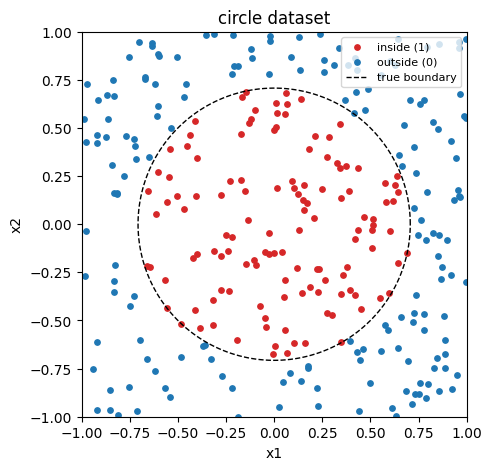

In [24]:
print(X.shape, y.shape)          # (300, 2) (300,)
print("inside ratio:", y.mean())  # 약 0.39
plot_data(X, y)

이러한 종류의 데이터는 선형 경계로 풀 수 없기 때문에 feature engieering을 사용해서 차원을 늘리는 feature engineering을 사용해보겠습니다. 아래의 코드는 feature를 늘리는 함수를 받아서 log likelihood로 fitting하는 함수입니다.

In [25]:
import numpy as np


def sigmoid(z):
    return 1 / (1 + np.exp(-z))

class FeatureEngineer:
    def __init__(self, feature_fn, learning_rate=1.0, epochs=5000):
        self.feature_fn = feature_fn
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.theta = None
        self.loss_history = []

    def mapping_function(self, X):
        return self.feature_fn(np.asarray(X, dtype=float))

    def explicit_kernel(self, X, Y):
        return self.mapping_function(X) @ self.mapping_function(Y).T

    def fit(self, X, y):
        y = np.asarray(y, dtype=float)
        phi = self.mapping_function(X)      # 한 번만 계산
        n, f = phi.shape

        self.theta = np.zeros(f)
        self.loss_history = []
        eps = 1e-12

        for _ in range(self.epochs):
            p = sigmoid(phi @ self.theta)
            grad = phi.T @ (y - p) / n
            self.theta = self.theta + self.learning_rate * grad

            loss = -np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))
            self.loss_history.append(loss)

        return self

    def predict_proba(self, X):
        return sigmoid(self.mapping_function(X) @ self.theta)

    def predict(self, X):
        return (self.predict_proba(X) > 0.5).astype(float)

    def score(self, X, y):
        return np.mean(self.predict(X) == y)

In [26]:
def train_test_split(X,y,test_ratio=0.3,seed = 0):

    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(X))

    n_test = int(len(X) * test_ratio)

    test_idx = idx[:n_test]
    train_idx = idx[n_test:]

    return X[train_idx],X[test_idx],y[train_idx],y[test_idx]

def plot_boundary(model, X, y, ax, title):
    g = np.linspace(-1, 1, 200)
    G1, G2 = np.meshgrid(g, g)
    grid = np.column_stack([G1.ravel(), G2.ravel()])
    Z = model.predict_proba(grid).reshape(G1.shape)

    ax.contourf(G1, G2, Z, levels=[0, 0.5, 1], colors=["tab:blue", "tab:red"], alpha=0.2)
    ax.contour(G1, G2, Z, levels=[0.5], colors="k")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], c="tab:red", s=10)
    ax.scatter(X[y == 0, 0], X[y == 0, 1], c="tab:blue", s=10)
    ax.set_aspect("equal")
    ax.set_title(title)

raw_feature는 그대로 넣는 함수
poly_features는 X의 feature를 조합해서 만든 새로운 X



In [30]:
def raw_features(X):
    # [1, x1, x2]
    return np.column_stack([np.ones(len(X)), X])

def minimal_poly(X):
    x1, x2 = X[:, 0], X[:, 1]
    return np.column_stack([np.ones(len(X)), x1**2, x2**2])
        
def poly_features(X):
    # [1, x1, x2, x1², x2², x1*x2]
    x1, x2 = X[:, 0], X[:, 1]
    return np.column_stack([np.ones(len(X)), x1, x2, x1**2, x2**2, x1 * x2])

train: (210, 2)  test: (90, 2)
[raw ] train acc = 0.476 | test acc = 0.489 | final loss = 0.6801
        theta = [-0.22 -0.34 -0.18]
[poly] train acc = 0.981 | test acc = 1.000 | final loss = 0.1539
        theta = [ 4.51 -0.2   0.04 -8.3  -8.85  0.13]
[minal_poly] train acc = 0.995 | test acc = 0.989 | final loss = 0.1538
        theta = [ 4.51 -8.37 -8.84]


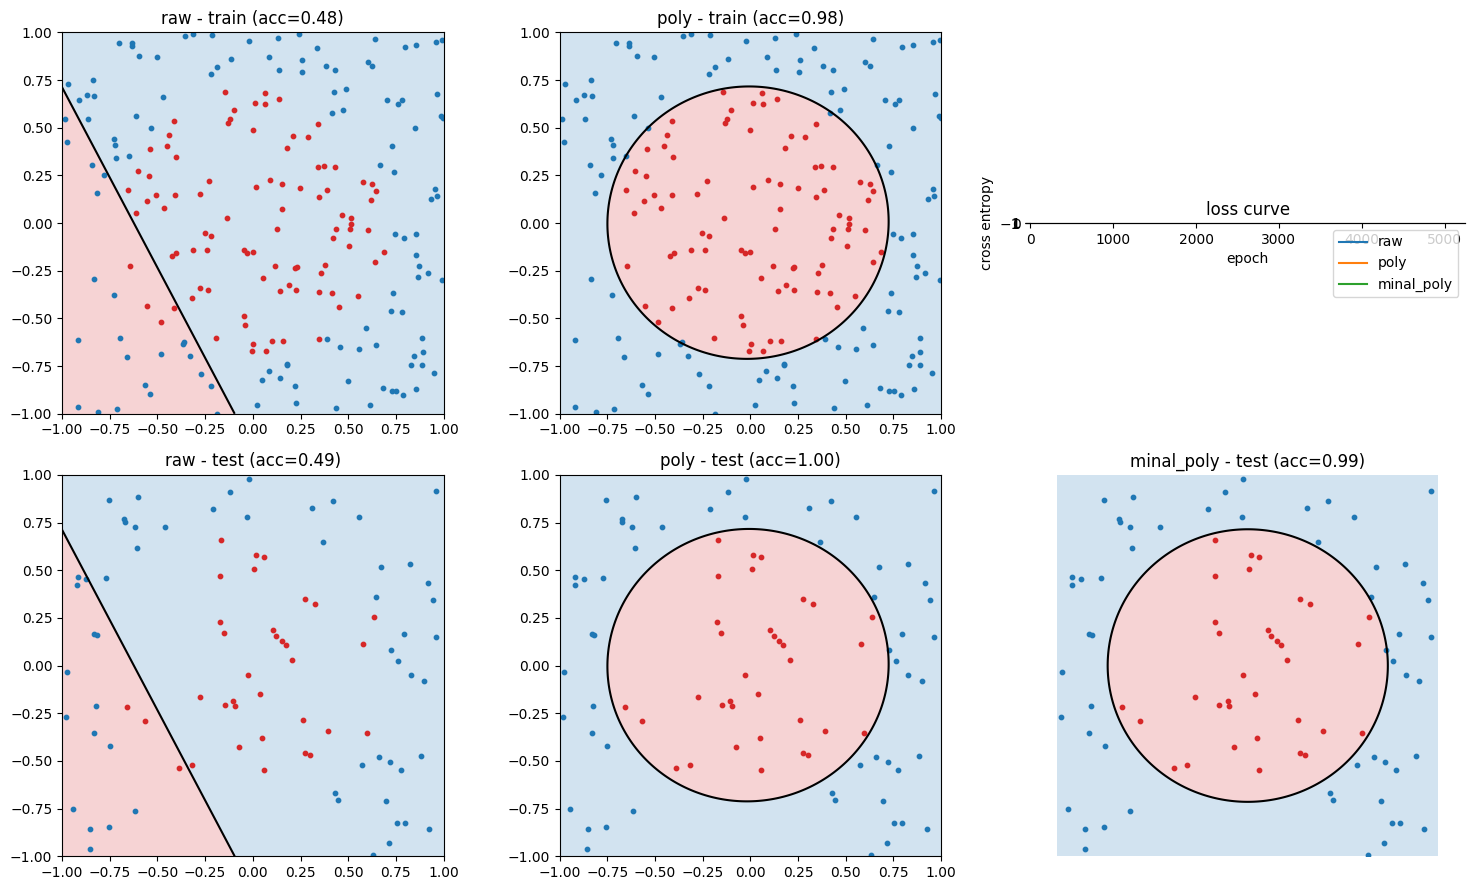

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_ratio=0.3)
print("train:", X_train.shape, " test:", X_test.shape)

feature_fns = {"raw": raw_features, "poly": poly_features,"minal_poly" : minimal_poly}
models = {}


for name,fn in feature_fns.items():
    model = FeatureEngineer(fn,learning_rate= 0.1,epochs=5000)

    model.fit(X_train,y_train)
    
    models[name] = model
    print(f"[{name:4s}] train acc = {model.score(X_train, y_train):.3f}"
            f" | test acc = {model.score(X_test, y_test):.3f}"
            f" | final loss = {model.loss_history[-1]:.4f}")
    print("        theta =", np.round(model.theta, 2))


fig, ax = plt.subplots(2, 3, figsize=(15, 9))

for col, name in enumerate(feature_fns):
    m = models[name]
    plot_boundary(m, X_train, y_train, ax[0, col],
                f"{name} - train (acc={m.score(X_train, y_train):.2f})")
    plot_boundary(m, X_test, y_test, ax[1, col],
                f"{name} - test (acc={m.score(X_test, y_test):.2f})")

for name, m in models.items():
    ax[0, 2].plot(m.loss_history, label=name)
ax[0, 2].set_title("loss curve")
ax[0, 2].set_xlabel("epoch")
ax[0, 2].set_ylabel("cross entropy")
ax[0, 2].legend()
ax[1, 2].axis("off")

plt.tight_layout()
plt.show()

원형경계가

$
[1, x_1, x_2 ,x_1^2, x_2^2, x_1 \cdot x_2 ]
$

이러한 feature로 풀리는 이유는 대략 이런 것 같다

$
x_1^2 + x_2^2 < r^2
$

이러한 경계에서

r^2 - x_1^2 - x_2^2 >0 

이 식이 0 보다 크냐 작냐로 생각해볼 수 있다
위의 feature들을 $\theta$ 에 대해서 선형결합 해보면

$
r^2  + \theta_1 \cdot x_1 + \theta_2 \cdot x_2 - \theta_3 \cdot x_1^2 - \theta_4 \cdot x_2^2 + \theta_5 \cdot x_1 \cdot x_2 > 0
$

$\theta$ 를 잘 학습하면 풀릴 수 있는 것처럼 보이기 때문에 minimal_poly함수를 더 만들어서 실험해보았다




여기서 문제는 mapping 함수 φ의 계산량이다.

$$
\theta := \theta + \alpha \sum_{i=1}^{n} \left( y^{(i)} - \sigma\!\left(\theta^T \phi(x^{(i)})\right) \right) \phi(x^{(i)}) \tag{5.3'}
$$

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

맨 처음 초기화에선 $\theta$ = 0 이므로



$$
\theta = \sum_{i=1}^{n} \beta_i \, \phi(x^{(i)})
$$

$$
\begin{aligned}
\theta &:= \theta + \alpha \sum_{i=1}^{n} \left( y^{(i)} - \theta^T \phi(x^{(i)}) \right) \phi(x^{(i)}) \\
&= \sum_{i=1}^{n} \beta_i \, \phi(x^{(i)}) + \alpha \sum_{i=1}^{n} \left( y^{(i)} - \theta^T \phi(x^{(i)}) \right) \phi(x^{(i)}) \\
&= \sum_{i=1}^{n} \underbrace{\left( \beta_i + \alpha \left( y^{(i)} - \theta^T \phi(x^{(i)}) \right) \right)}_{\text{new } \beta_i} \phi(x^{(i)})
\end{aligned}
\tag{5.7}
$$

위 식에서 새로운 $\beta_i$ 는 이전 값에 다음과 같이 의존한다.

$$
\beta_i := \beta_i + \alpha \left( y^{(i)} - \theta^T \phi(x^{(i)}) \right) \tag{5.8}
$$

여기서 우변에는 아직 이전 $\theta$ 가 남아 있다.
$\theta = \sum_{j=1}^{n} \beta_j \, \phi(x^{(j)})$ 로 치환하면 다음을 얻는다.

$$
\forall i \in \{1, \dots, n\}, \quad
\beta_i := \beta_i + \alpha \left( y^{(i)} - \sum_{j=1}^{n} \beta_j \, \phi(x^{(j)})^T \phi(x^{(i)}) \right)
$$

여기를 보자

$$
\sum_{j=1}^{n} \beta_j \, \phi(x^{(j)})^T \phi(x^{(i)})$$

여기를 보면 내적 연산이 나온다


모든 데이터 쌍 $(i, j)$ 에 대해 내적 $\phi(x^{(j)})^T \phi(x^{(i)})$ 가 필요하다.
$\beta$ 를 한 번 업데이트(전체 $\beta_1, \dots, \beta_n$ 갱신)하려면 내적이 $n^2$ 개 필요하다.

이 내적 값은 $\beta$ 가 바뀌어도 변하지 않으므로, 한 번만 계산해서
커널 행렬 $K_{ij} = \phi(x^{(i)})^T \phi(x^{(j)})$ 로 저장해 두면 된다.

그런데 내적 하나를 구하려면 $\phi$ 로 $p$ 차원 벡터를 만들어야 하므로
$K$ 를 만드는 데 $O(n^2 p)$ 가 든다.

p는 초기 x차원의 크기에 따라 달라지는데

$$
\phi(x) =
\begin{bmatrix}
1 \\
x_1 \\
x_2 \\
\vdots \\
x_1^2 \\
x_1 x_2 \\
x_1 x_3 \\
\vdots \\
x_2 x_1 \\
\vdots \\
x_1^3 \\
x_1^2 x_2 \\
\vdots
\end{bmatrix}.
$$

이러한 mapping 함수라면 p = d^3 정도가 되기 때문에 원래 데이터 차원이 1000개 였다면 p는 1000^3 크기가 되어 연산량이 $O(n^2 d^3)$ 이된다
어마무시하다

그래서 메핑함수의 내적과 결과가 일치하는 함수를 찾아내어 내적을 연산하지 않을 것이다 그것이 커널 트릭이다

